In [1]:
!pip install scipy numpy pandas matplotlib seaborn

In [3]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.io import loadmat

In [5]:
dataset_path = r"C:\Users\suthi\Downloads\AI_Motor_Predictive_Maintenance\datasets"

normal_path = os.path.join(dataset_path, "Normal")
outer_race_path = os.path.join(dataset_path, "Outer_Race")

print("Dataset folder exists:", os.path.exists(dataset_path))
print("Normal folder exists:", os.path.exists(normal_path))
print("Outer Race folder exists:", os.path.exists(outer_race_path))

Dataset folder exists: True
Normal folder exists: True
Outer Race folder exists: True


In [7]:
print("NORMAL FILES:")
print(os.listdir(normal_path))

print("\nOUTER RACE FILES:")
print(os.listdir(outer_race_path))

NORMAL FILES:
['Normal_0.mat', 'Normal_1.mat', 'Normal_2.mat', 'Normal_3.mat']

OUTER RACE FILES:
['0R007_12_0HP.mat', '0R007_12_1HP.mat', '0R007_3_0HP.mat', '0R007_3_1HP.mat', '0R007_6_0HP.mat', '0R007_6_1HP.mat', '0R021_12_0HP.mat', '0R021_6_0HP.mat', 'OR021_3_0HP.mat']


In [11]:
from scipy.io import loadmat

file_path = os.path.join(outer_race_path, "0R007_6_0HP.mat")

data = loadmat(file_path)

print(data.keys())

dict_keys(['__header__', '__version__', '__globals__', 'X130_DE_time', 'X130_FE_time', 'X130_BA_time', 'X130RPM'])


Here's what they mean:
Variable	Meaning
X130_DE_time	Drive-End vibration signal
X130_FE_time	Fan-End vibration signal
X130_BA_time	Base vibration signal
X130RPM	Motor rotational speed
__header__	MATLAB file information
__version__	MATLAB file version
__globals__	MATLAB global variables

For our first model, we'll use Drive-End (DE) vibration data.m


In [18]:
#Extract the Drive-End signal
import numpy as np

# Extract Drive-End vibration signal
signal = data['X130_DE_time'].squeeze()

# Extract motor RPM
rpm = data['X130RPM'].squeeze()

print("Signal shape:", signal.shape)
print("Total samples:", len(signal))
print("Motor RPM:", rpm)

print("\nFirst 10 vibration values:")
print(signal[:10])

Signal shape: (121991,)
Total samples: 121991
Motor RPM: 1796

First 10 vibration values:
[ 0.00852784  0.4235496   0.01299481 -0.26517535  0.23715529  0.59085778
 -0.09299411 -0.4069      0.27938842  0.4369505 ]


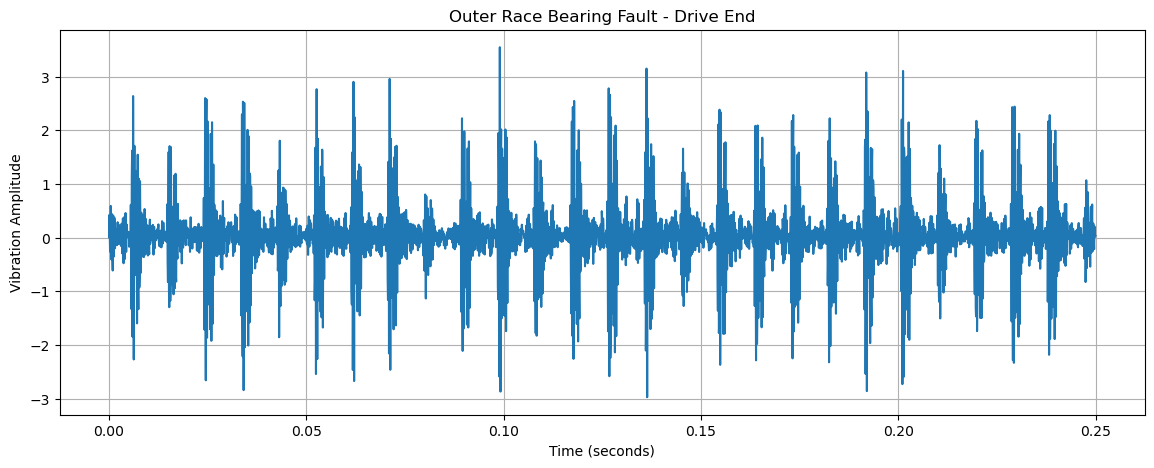

In [20]:
import matplotlib.pyplot as plt

sampling_rate = 12000

# Generate time values
time = np.arange(len(signal)) / sampling_rate

# Plot first 3000 samples
plt.figure(figsize=(14, 5))

plt.plot(time[:3000], signal[:3000])

plt.title("Outer Race Bearing Fault - Drive End")
plt.xlabel("Time (seconds)")
plt.ylabel("Vibration Amplitude")

plt.grid(True)
plt.show()

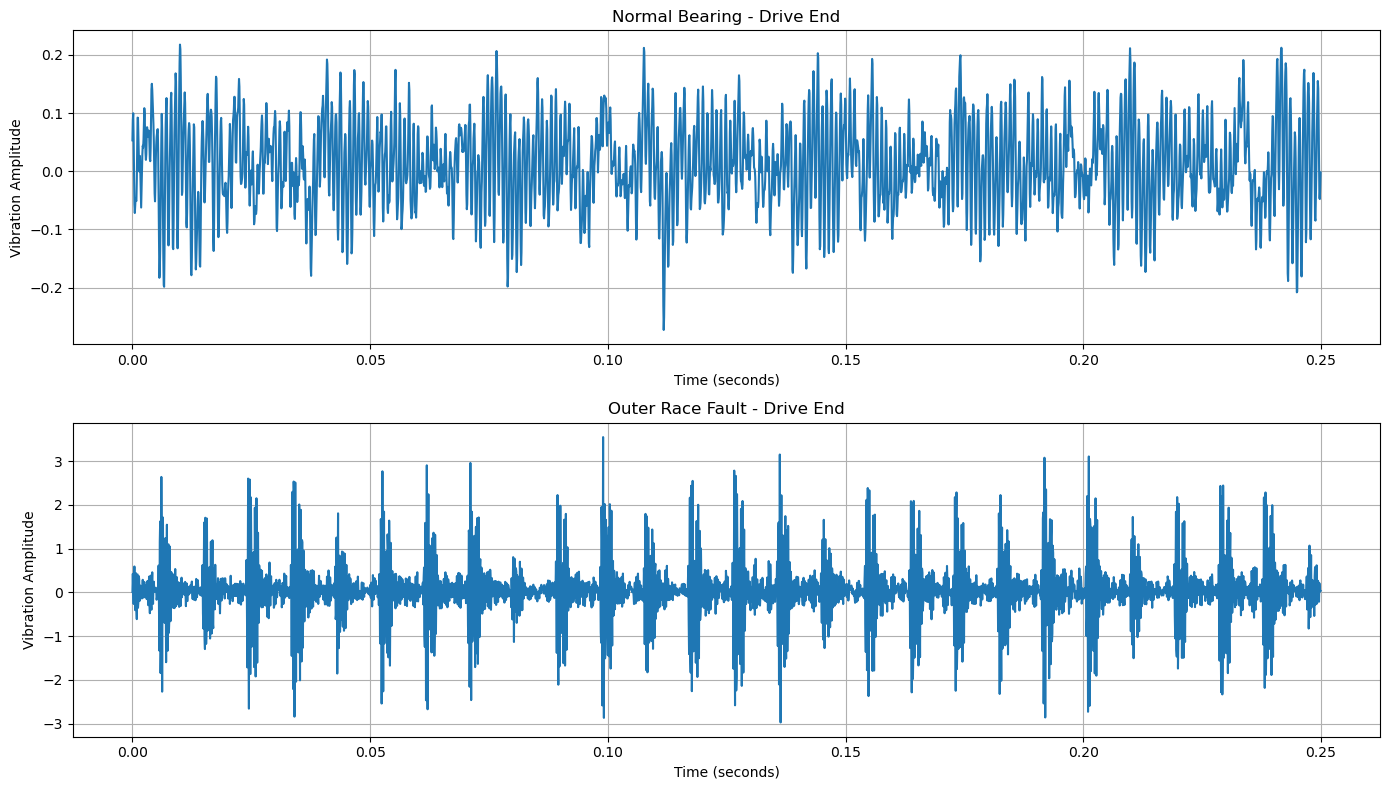

In [22]:
from scipy.io import loadmat
import numpy as np
import matplotlib.pyplot as plt
import os

# Sampling frequency
fs = 12000

# Load Normal bearing data
normal_file = os.path.join(normal_path, "Normal_0.mat")
normal_data = loadmat(normal_file)

# Find Drive-End signal variable automatically
normal_key = [k for k in normal_data.keys()
              if k.endswith("_DE_time")][0]

normal_signal = normal_data[normal_key].squeeze()

# Load Outer Race bearing data
outer_file = os.path.join(
    outer_race_path,
    "0R007_6_0HP.mat"
)

outer_data = loadmat(outer_file)

outer_key = [k for k in outer_data.keys()
             if k.endswith("_DE_time")][0]

outer_signal = outer_data[outer_key].squeeze()

# Select first 3000 samples
samples = 3000

time = np.arange(samples) / fs

# Plot comparison
plt.figure(figsize=(14, 8))

plt.subplot(2, 1, 1)
plt.plot(time, normal_signal[:samples])
plt.title("Normal Bearing - Drive End")
plt.xlabel("Time (seconds)")
plt.ylabel("Vibration Amplitude")
plt.grid(True)

plt.subplot(2, 1, 2)
plt.plot(time, outer_signal[:samples])
plt.title("Outer Race Fault - Drive End")
plt.xlabel("Time (seconds)")
plt.ylabel("Vibration Amplitude")
plt.grid(True)

plt.tight_layout()
plt.show()

In [24]:
# 3. Calculate basic vibration statistics
def calculate_features(signal):

    rms = np.sqrt(np.mean(signal ** 2))
    std = np.std(signal)
    peak = np.max(np.abs(signal))

    return rms, std, peak


normal_rms, normal_std, normal_peak = calculate_features(normal_signal)

outer_rms, outer_std, outer_peak = calculate_features(outer_signal)

print("NORMAL BEARING")
print("RMS:", normal_rms)
print("Standard Deviation:", normal_std)
print("Peak Amplitude:", normal_peak)

print("\nOUTER RACE BEARING")
print("RMS:", outer_rms)
print("Standard Deviation:", outer_std)
print("Peak Amplitude:", outer_peak)

NORMAL BEARING
RMS: 0.07376396805784112
Standard Deviation: 0.0726870986839877
Peak Amplitude: 0.31125415384615385

OUTER RACE BEARING
RMS: 0.6695055877685285
Standard Deviation: 0.6691044871630503
Peak Amplitude: 3.630425149700599


In [26]:
# 3. Next step: Feature extraction
#Step 10: Write your first feature extraction function
from scipy.stats import kurtosis, skew

def extract_features(signal):

    features = {
        "Mean": np.mean(signal),
        "RMS": np.sqrt(np.mean(signal ** 2)),
        "Standard Deviation": np.std(signal),
        "Variance": np.var(signal),
        "Minimum": np.min(signal),
        "Maximum": np.max(signal),
        "Peak-to-Peak": np.ptp(signal),
        "Kurtosis": kurtosis(signal),
        "Skewness": skew(signal),
        "Crest Factor": np.max(np.abs(signal)) / np.sqrt(np.mean(signal ** 2))
    }

    return features

In [28]:
normal_features = extract_features(normal_signal)
outer_features = extract_features(outer_signal)

feature_table = pd.DataFrame({
    "Normal": normal_features,
    "Outer Race": outer_features
})

print(feature_table)

                      Normal  Outer Race
Mean                0.012558    0.023171
RMS                 0.073764    0.669506
Standard Deviation  0.072687    0.669104
Variance            0.005283    0.447701
Minimum            -0.286638   -3.408701
Maximum             0.311254    3.630425
Peak-to-Peak        0.597892    7.039126
Kurtosis           -0.235757    4.649435
Skewness           -0.035411    0.056946
Crest Factor        4.219596    5.422546


In [30]:
#3. Next step: Signal segmentation (windowing)
# Signal segmentation

window_size = 2048
overlap = 1024

def create_windows(signal):

    windows = []

    step = window_size - overlap

    for start in range(0, len(signal) - window_size + 1, step):

        end = start + window_size

        window = signal[start:end]

        windows.append(window)

    return np.array(windows)


# Segment Normal signal
normal_windows = create_windows(normal_signal)

# Segment Outer Race signal
outer_windows = create_windows(outer_signal)


print("Normal windows:", normal_windows.shape)
print("Outer Race windows:", outer_windows.shape)

print("Samples per window:", window_size)

Normal windows: (237, 2048)
Outer Race windows: (118, 2048)
Samples per window: 2048


2. Next step: Extract features from every window
Previously, we calculated 10 features from an entire recording.

Now, we'll calculate those same 10 features separately for every window.

For example:
- Normal window 1 → 10 features
- Normal window 2 → 10 features
- Outer Race window 1 → 10 features
- Outer Race window 2 → 10 features
This creates the structured dataset needed for machine learning.

In [33]:
# Step 10: Create a feature extraction function
from scipy.stats import kurtosis, skew

def extract_features(signal):

    features = {
        "Mean": np.mean(signal),
        "RMS": np.sqrt(np.mean(signal ** 2)),
        "Standard_Deviation": np.std(signal),
        "Variance": np.var(signal),
        "Minimum": np.min(signal),
        "Maximum": np.max(signal),
        "Peak_to_Peak": np.ptp(signal),
        "Kurtosis": kurtosis(signal),
        "Skewness": skew(signal),
        "Crest_Factor": np.max(np.abs(signal)) / (
            np.sqrt(np.mean(signal ** 2)) + 1e-10
        )
    }

    return features

In [35]:
#Step 11: Extract features from all windows
feature_rows = []

# Normal bearing windows
for i, window in enumerate(normal_windows):

    features = extract_features(window)

    features["Label"] = "Normal"
    features["Window_ID"] = i
    features["Source_File"] = "Normal_0.mat"

    feature_rows.append(features)


# Outer Race bearing windows
for i, window in enumerate(outer_windows):

    features = extract_features(window)

    features["Label"] = "Outer_Race"
    features["Window_ID"] = i
    features["Source_File"] = "0R007_6_0HP.mat"

    feature_rows.append(features)


# Convert into DataFrame
feature_df = pd.DataFrame(feature_rows)

print("Dataset shape:", feature_df.shape)

print("\nFirst five rows:")
print(feature_df.head())

Dataset shape: (355, 13)

First five rows:
       Mean       RMS  Standard_Deviation  Variance   Minimum   Maximum  \
0  0.012005  0.073256            0.072266  0.005222 -0.272869  0.217794   
1  0.013116  0.074507            0.073344  0.005379 -0.272869  0.212370   
2  0.012790  0.079035            0.077993  0.006083 -0.226765  0.223010   
3  0.012148  0.077916            0.076964  0.005923 -0.226765  0.223010   
4  0.011959  0.074338            0.073370  0.005383 -0.202148  0.219255   

   Peak_to_Peak  Kurtosis  Skewness  Crest_Factor   Label  Window_ID  \
0      0.490663 -0.045824 -0.137322      3.724845  Normal          0   
1      0.485239 -0.116338 -0.010099      3.662321  Normal          1   
2      0.449775 -0.184580 -0.062348      2.869171  Normal          2   
3      0.449775 -0.150657 -0.103819      2.910361  Normal          3   
4      0.421403 -0.221760  0.025960      2.949440  Normal          4   

    Source_File  
0  Normal_0.mat  
1  Normal_0.mat  
2  Normal_0.mat  
3

In [37]:
print("Dataset shape:", feature_df.shape)

print("\nClass distribution:")
print(feature_df["Label"].value_counts())

print("\nMissing values:")
print(feature_df.isnull().sum())

print("\nDataset information:")
print(feature_df.info())

Dataset shape: (355, 13)

Class distribution:
Label
Normal        237
Outer_Race    118
Name: count, dtype: int64

Missing values:
Mean                  0
RMS                   0
Standard_Deviation    0
Variance              0
Minimum               0
Maximum               0
Peak_to_Peak          0
Kurtosis              0
Skewness              0
Crest_Factor          0
Label                 0
Window_ID             0
Source_File           0
dtype: int64

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 355 entries, 0 to 354
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Mean                355 non-null    float64
 1   RMS                 355 non-null    float64
 2   Standard_Deviation  355 non-null    float64
 3   Variance            355 non-null    float64
 4   Minimum             355 non-null    float64
 5   Maximum             355 non-null    float64
 6   Peak_to_Peak        